# Wine Variety Classification with k-NN and PCA

**Contents**

1. Business Understanding (objectives, problem statement, stakeholders, success criteria)
2. Data Understanding
3. Data Preparation (split, scaling, PCA)
4. Modeling (baselines and hyperparameter tuning)
5. Evaluation
6. Deployment and Recommendations

# Business Understanding

Background

A premium wine distributor receives, stores and sells wines from several grape varieties (cultivars). Each lot must be assigned to the correct variety so that it is:

* **stored and picked correctly** (inventory management),
* **checked against its label and supplier documentation** (quality control and authenticity),
* **priced, described and marketed accurately** (sales and procurement).

At present, verifying a variety depends on paperwork and expert tasting, which is slow, subjective and hard to scale. Every incoming lot is already analysed in the laboratory, so **13 measurable chemical properties** exist for each wine. The question is whether those measurements alone can identify the variety reliably and automatically.

## Business objectives

1. Automatically classify a wine into its variety from its chemical profile.
2. Reduce the manual effort and turnaround time of variety verification.
3. Detect likely mislabelled or mixed-up lots early, before they reach customers.
4. Understand *which* measurements matter most, so that lab testing can be focused.

## Problem statement

 *Can a model trained on the chemical analysis of wines predict the grape variety (Barolo, Grignolino or Barbera) accurately enough to support inventory management and quality control, and which model configuration is the most reliable?*

This is a **supervised, multi-class classification** problem with three classes and 13 continuous predictors. We use **k-Nearest Neighbors (k-NN)** combined with **Principal Component Analysis (PCA)**, and tune the pipeline systematically with cross-validated grid search.

**Why k-NN + PCA?**

* k-NN is simple, easy to explain to non-technical stakeholders ("a new wine is labelled like the most chemically similar wines we already know") and needs no training phase.
* k-NN is distance-based, so it suffers when features are correlated, noisy or on different scales. Standardisation and PCA address these issues directly.
* PCA compresses the 13 correlated measurements into a few uncorrelated components, which reduces noise and makes the data **visualisable** for business users.

## Stakeholders
1. Inventory managers: Correct storage location and stock counts per variety
2. Quality Control: Verify supplier claims, detect mislabelled lots
3. Sales and marketing: Accurate product descriptions and pricing tiers

## Assumptions and Risks
* The dataset is small (178 wines) and covers three varieties only. A wine from any other variety will still be forced into one of these three classes.
* The chemical measurements come from a standardised laboratory process, so new data must be measured the same way.
* Different mistakes may have different costs (for example, a premium wine labelled as a cheaper one). No cost information was provided, so all errors are treated as equally costly here.

In [49]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.feature_selection import f_classif
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import (
    GridSearchCV,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

## Data Understanding


In [50]:
# Load the dataset
wine_dataset = pd.read_csv("wine.csv")
df = wine_dataset.copy()

# Class names, as defined in the data description below
class_names = ["Barolo", "Grignolino", "Barbera"]

print("Wine dataset shape", df.shape)
wine_dataset.head()

Wine dataset shape (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


The dataset contains the results of a chemical analysis of wines grown in the same region of Italy but derived from three different cultivars. Each row is one wine; the 13 columns are measured chemical properties and `target` is the grape variety. (The original description said the data shows the effect of chemicals on *quality*, but the target here is the **variety**, not a quality score.)

### **What every feature stands for**

1. *Alcohol*: Alcoholic content. Presumably a percentage, implying it can be scaled from 0-1
2. *Malic Acid*: Concentration of malic acid. The higher the concentration, the better the taste
3. *Alcalinity of ash*: Measures the alkalinity of the wine. It helps in determining the buffering capacity and overal acidity balance of the wine
4. *Magnessium* It indicates the concentration of magnessium. It is essential in yeast fermentation.
5. *Total phonols*: Measures combined amount of all phenolic compounds. They affect wine's colour, mouthfeel and flavour
6. *Flavanoids**: Measures the phelonic compounds responsible for colour, bitterness, and astrigency
7. *Non flavanoid phenols*: Measures phelonic compounds that do not belong to the flavanoid family. They contribute to subtle flavour nuances and chemical stability
8. *Proanthocyanins** Measures condensed tannins, which are a specific class of flavanoids. Responsible for astrigency and help stabilize wine colour
9.  *Colour Intensity*: Colour saturation measured via light absorbance.
10. *Hue* Ratio of light absorbance at different wavelengths
11. *OD280/0D315*: Measures the ration of ultraviolet abssorbance at 280nm to 315nm. It estimates the concentration of proteins and phenolic compounds
12. *Proline* Measures the concentration of proline, the most abundant amino acid in wine. Higher indicates riper grapes
13. *Ash*: Total inorganic matter left ebind after the wine is evaporated.
14. *target*: Grape variety `0 = Barolo, high alcohol, rich in phenols and proline`, `1 = Grignolio, lower alcohol, lower colour intensity`, `2 = Barbera, high acidity, deep colour tart profile`

In [51]:
# Remove duplicate rows
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)


Duplicate rows: 0
Shape after removing duplicates: (178, 14)


In [ ]:
# Check for missing values and perform summary statistics
print(df.isna().sum())

# Perform summary statistics
df.describe()


alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


There are no duplicate rows and no missing values, so no rows need to be removed and no imputation is required. The summary statistics show that the features live on very different scales (`proline` is in the hundreds to over a thousand, `hue` is around 1, `nonflavanoid_phenols` is below 1). Because k-NN relies on distances, this matters a great deal and is addressed in Data Preparation.

In [ ]:
# Calculate the skewness and kurtosis
num_df = df.drop(columns = "target")

skewness_kurtosis = pd.DataFrame({
    "Skewnesss": num_df.skew(),
    "Kurtosis": num_df.kurt()
})

skewness_kurtosis

,Skewnesss,Kurtosis
alcohol,-0.051482,-0.852500
malic_acid,1.039651,0.299207
ash,-0.176699,1.143978
alcalinity_of_ash,0.213047,0.487942
magnesium,1.098191,2.104991
total_phenols,0.086639,-0.835627
flavanoids,0.025344,-0.880382
nonflavanoid_phenols,0.450151,-0.637191
proanthocyanins,0.517137,0.554649
color_intensity,0.868585,0.381522


Most features are close to symmetric. `malic_acid` and `magnesium` are the most right-skewed (skewness about 1.0 to 1.1), and `magnesium` has the heaviest tails (kurtosis about 2.1). `color_intensity`, `proline` and `proanthocyanins` are mildly right-skewed. None of the skews is severe, so no transformation is applied; standardisation is sufficient for k-NN.

target
0    33.1
1    39.9
2    27.0
Name: proportion, dtype: float64

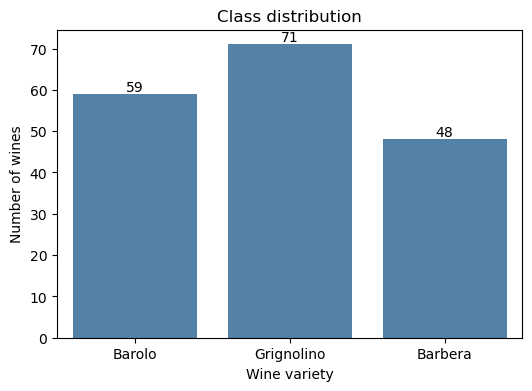

In [52]:
# Determine the value counts of the target feature
display((df["target"].value_counts(normalize = True).sort_index() * 100).round(1))

plt.figure(figsize = (6, 4))
ax = sns.countplot(x = df["target"].map(dict(enumerate(class_names))), order = class_names, color = "steelblue")
ax.bar_label(ax.containers[0])
plt.xlabel("Wine variety")
plt.ylabel("Number of wines")
plt.title("Class distribution")
plt.show()

## Relationship between features


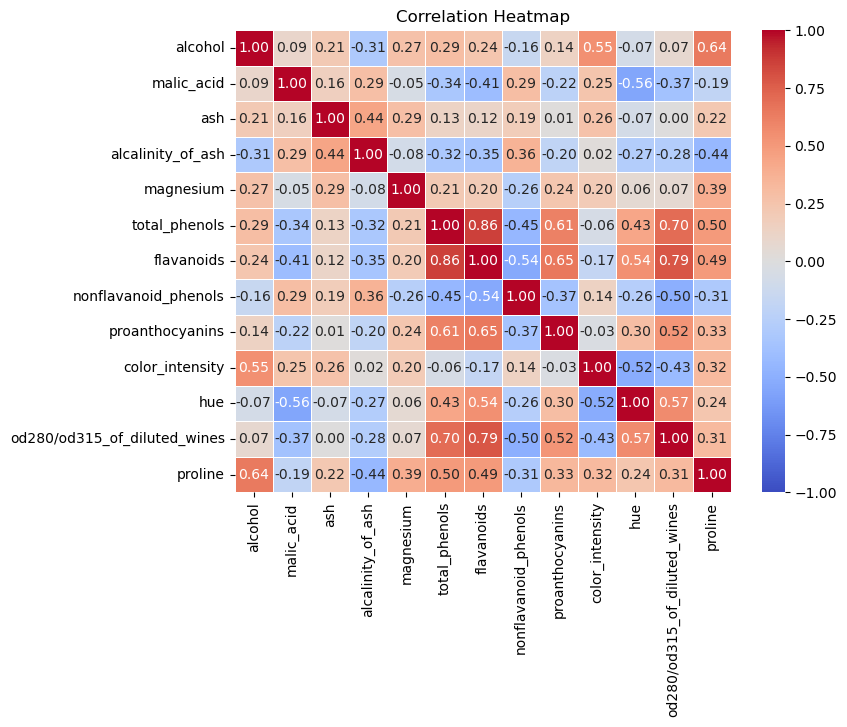

In [26]:
# Perform correlation matrix
corr = num_df.corr()

plt.figure(figsize = (8, 6))
sns.heatmap(
    corr,
    annot = True,
    fmt = ".2f",
    cmap = "coolwarm",
    vmin = -1,
    vmax = 1,
    center = 0,
    linewidths = 0.5
)
plt.title("Correlation Heatmap")
plt.show()

Several features are strongly correlated, notably `total_phenols` with `flavanoids` (about 0.86) and `flavanoids` with `od280/od315_of_diluted_wines` (about 0.79). The phenol-related measurements largely carry the same information. Correlated features give the same signal multiple votes in a distance calculation, which is exactly the situation where **PCA** helps: it replaces correlated features with a smaller set of uncorrelated components.

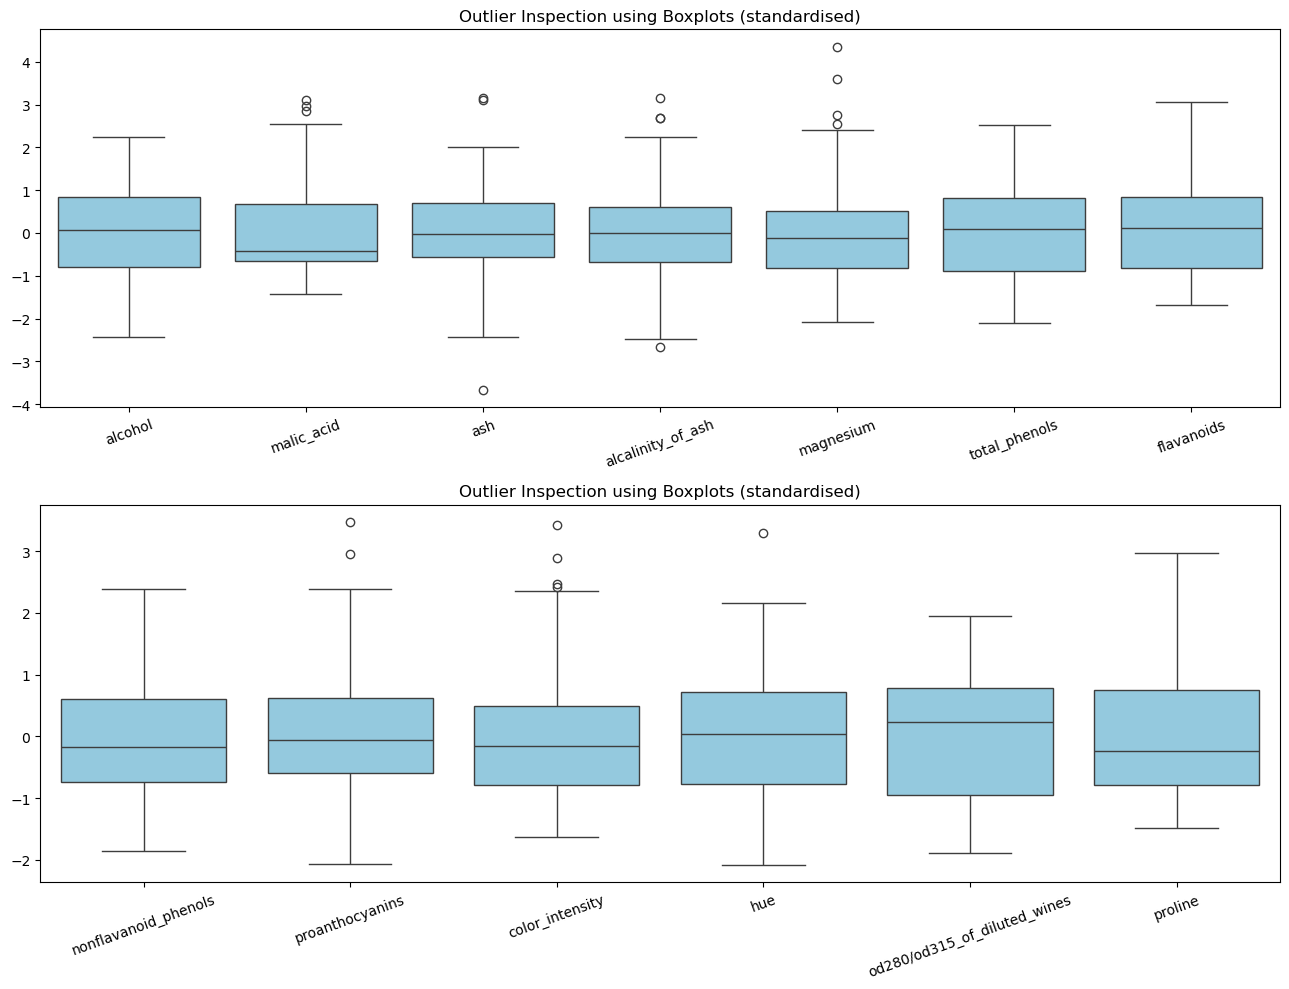

malic_acid           3
ash                  3
alcalinity_of_ash    4
magnesium            4
proanthocyanins      2
color_intensity      4
hue                  1
Name: Outliers (1.5 x IQR rule), dtype: int64

In [54]:
# Use boxplots to check outliers (features standardised so they fit on one axis)
num_scaled = (num_df - num_df.mean()) / num_df.std()

fig, axes = plt.subplots(2, 1, figsize = (13, 10))
sns.boxplot(data = num_scaled.iloc[:, :7], color = "skyblue", ax = axes[0]) # The first seven features
axes[0].set_title("Outlier Inspection using Boxplots (standardised)")
axes[0].tick_params(axis = "x", rotation = 20)

sns.boxplot(data = num_scaled.iloc[:, 7:], color = "skyblue", ax = axes[1]) # The last six features
axes[1].set_title("Outlier Inspection using Boxplots (standardised)")
axes[1].tick_params(axis = "x", rotation = 20)

plt.tight_layout()
plt.show()

# Count of points beyond 1.5 x IQR for every feature
q1, q3 = num_df.quantile(0.25), num_df.quantile(0.75)
iqr = q3 - q1
outlier_counts = ((num_df < q1 - 1.5 * iqr) | (num_df > q3 + 1.5 * iqr)).sum()
outlier_counts[outlier_counts > 0].rename("Outliers (1.5 x IQR rule)")



A small number of outliers appear in `malic_acid`, `ash`, `alcalinity_of_ash`, `magnesium`, `proanthocyanins`, `color_intensity` and `hue` (at most four per feature). With only 178 observations, and since these values are plausible chemical measurements rather than obvious errors, the outliers are **kept**. Removing them would throw away scarce data and could remove genuinely distinctive wines. Standardisation and k-NN's local voting limit their influence.

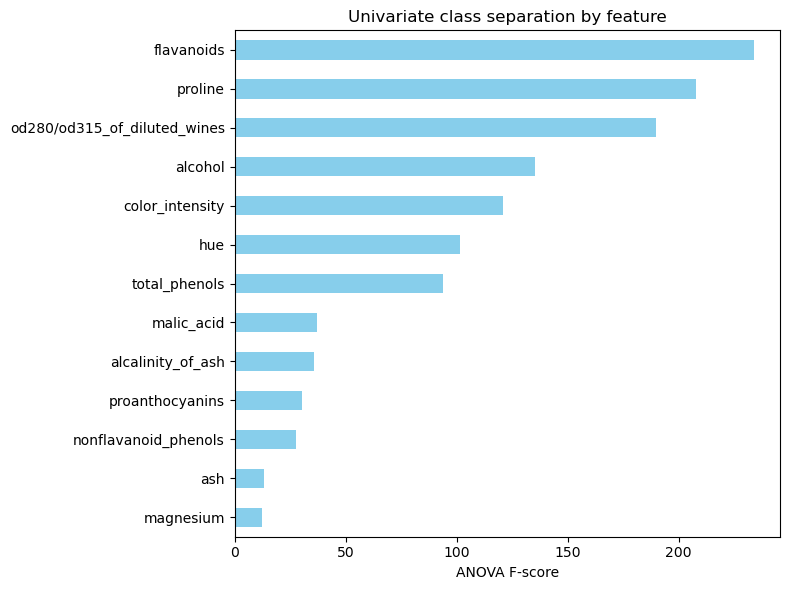

variety,Barbera,Barolo,Grignolino
alcohol,13.15,13.74,12.28
malic_acid,3.33,2.01,1.93
ash,2.44,2.46,2.24
alcalinity_of_ash,21.42,17.04,20.24
magnesium,99.31,106.34,94.55
total_phenols,1.68,2.84,2.26
flavanoids,0.78,2.98,2.08
nonflavanoid_phenols,0.45,0.29,0.36
proanthocyanins,1.15,1.90,1.63
color_intensity,7.40,5.53,3.09


In [56]:
# ANOVA F-score of every feature against the variety (higher = better separation between classes)
f_scores, _ = f_classif(num_df, df["target"])
f_scores = pd.Series(f_scores, index = num_df.columns).sort_values()

plt.figure(figsize = (8, 6))
f_scores.plot.barh(color = "skyblue")
plt.xlabel("ANOVA F-score")
plt.title("Univariate class separation by feature")
plt.tight_layout()
plt.show()

# Average chemical profile of every variety
df.assign(variety = df["target"].map(dict(enumerate(class_names)))).groupby("variety").mean().drop(columns = "target").T.round(2)

`flavanoids`, `proline`, `od280/od315_of_diluted_wines`, `alcohol` and `color_intensity` separate the three varieties best. The class profiles show why: Barbera has the lowest flavanoids and `od280/od315` values and the highest colour intensity, Barolo has by far the highest proline and flavanoids, and Grignolino has the lowest alcohol and colour intensity. The varieties therefore have distinct chemical fingerprints, which is encouraging for a distance-based classifier.

**Summary of Data Understanding:** the data is clean and complete, the classes are fairly balanced, the features are on very different scales and many are correlated, and the varieties have clearly different chemical profiles. These findings drive the preparation steps below: stratified split, standardisation and PCA.

# Data Preparation

The data is split **before** any scaling or PCA, so the test set stays completely unseen, as it would be for wines arriving in the future. The split is **stratified** to keep the class proportions identical in both sets.

In [57]:
X = num_df
y = df["target"]


# Train test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Training set:", X_train.shape, "| Test set:", X_test.shape)

Training set: (142, 13) | Test set: (36, 13)


## Scaling and PCA
Features have vastly different units, so they are standardised (mean 0, standard deviation 1) before any distance is computed. The scaler is **fitted on the training data only** and then applied to the test data with `transform`.


In [58]:
# Perform standard scaler. Features have vastly different units
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)   # transform only: never refit on test data


# Apply PCA
pca = PCA(n_components=0.90, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("PCA Dimensionality reduction")
print(f'Original features: {X_train.shape[1]}')
print(f'Reduced components (90% variance): {X_train_pca.shape[1]}')
print(
    f'Explained variance ratio: {np.sum(pca.explained_variance_ratio_):.4f}'
)

PCA Dimensionality reduction
Original features: 13
Reduced components (90% variance): 8
Explained variance ratio: 0.9209


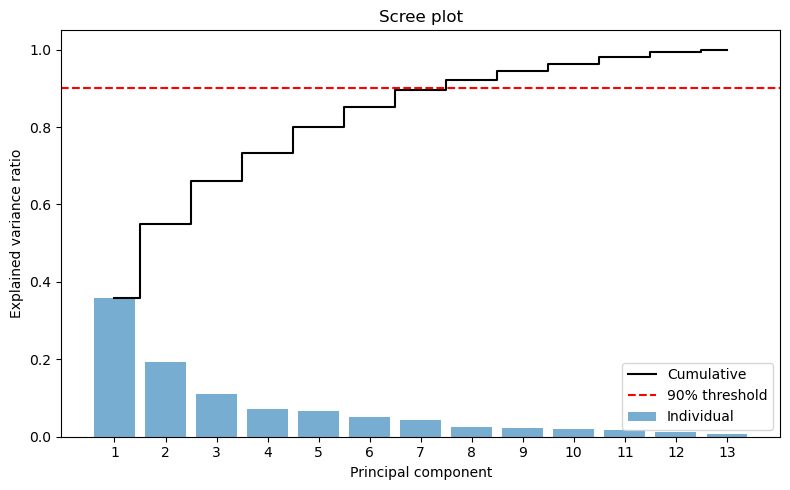

Cumulative variance for the first components:
1    0.358
2    0.551
3    0.661
4    0.734
5    0.801
6    0.852
7    0.896
8    0.921


In [59]:
# Investigate how much varinance each prinicpal carries
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
components = np.arange(1, len(cum_var) + 1)

plt.figure(figsize=(8, 5))
plt.bar(components, pca_full.explained_variance_ratio_, alpha=0.6, label="Individual")
plt.step(components, cum_var, where="mid", color="black", label="Cumulative")
plt.axhline(0.90, color="red", linestyle="--", label="90% threshold")
plt.xticks(components)
plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.title("Scree plot")
plt.legend()
plt.tight_layout()
plt.show()

print("Cumulative variance for the first components:")
print(pd.Series(cum_var, index=components).round(3).head(8).to_string())

the first two components capture about 55% of the variance and eight components are needed to reach 90%. The variance is spread fairly evenly, so PCA compresses this data moderately but not dramatically. How many components to keep is a modelling decision, and it is therefore tuned as a hyperparameter rather than fixed at 90% variance.

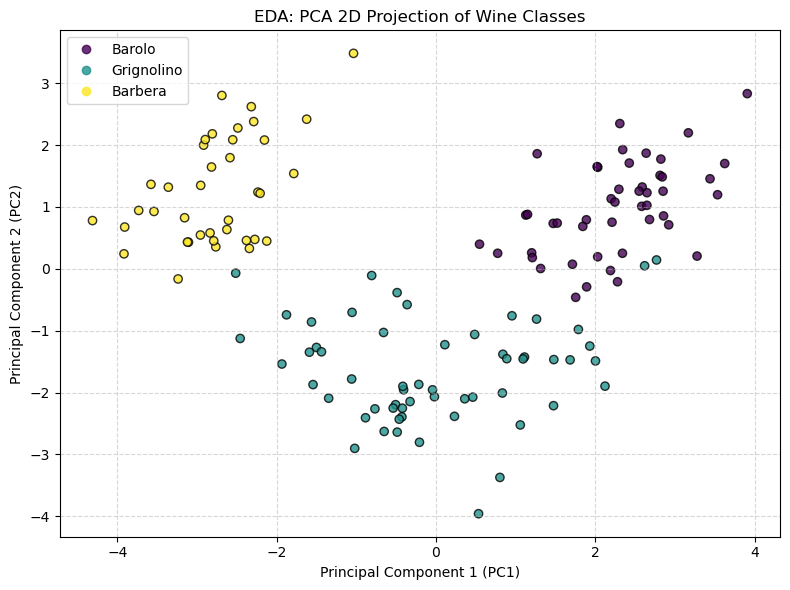

In [60]:
# Visualize the first 2 Principal Components to see class separability
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap='viridis', edgecolor='k', alpha=0.8
)
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.title('EDA: PCA 2D Projection of Wine Classes')
plt.legend(handles=scatter.legend_elements()[0], labels=class_names)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

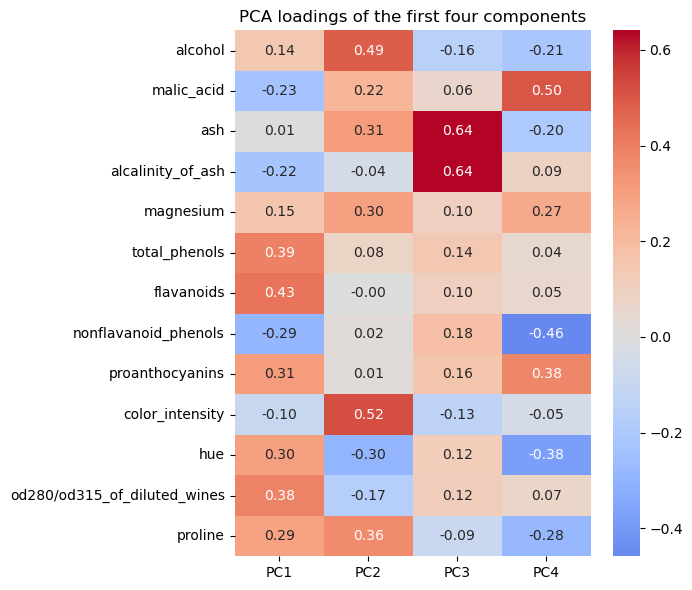

In [61]:
# What do the first principal components represent? (loadings = weight of each original feature)
loadings = pd.DataFrame(
    pca_full.components_[:4].T,
    index=X_train.columns,
    columns=[f"PC{i}" for i in range(1, 5)],
)

plt.figure(figsize=(7, 6))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("PCA loadings of the first four components")
plt.tight_layout()
plt.show()

PC1 is driven mainly by the phenol-related measurements (`flavanoids`, `total_phenols`, `od280/od315`, `proanthocyanins`) with the opposite sign for `nonflavanoid_phenols`, `malic_acid` and `alcalinity_of_ash`; PC2 is driven mainly by `color_intensity`, `alcohol` and `proline` (with smaller contributions from `ash` and `magnesium`). The components can therefore be described in business language as roughly a "phenolic richness" axis and a "colour and strength" axis.

# Modeling

## Baselines

Before tuning, we need reference points that show what each preparation step contributes. All scores are mean accuracy from repeated stratified 5-fold cross-validation (5 folds x 3 repeats) on the **training set only**.

In [62]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

baselines = {
    "k-NN, raw features (no scaling)": Pipeline([
        ("knn", KNeighborsClassifier()),
    ]),
    "k-NN + scaling": Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier()),
    ]),
    "k-NN + scaling + PCA (90% variance)": Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.90, random_state=RANDOM_STATE)),
        ("knn", KNeighborsClassifier()),
    ]),
}

baseline_results = []
for name, model in baselines.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    baseline_results.append({"Model": name, "CV accuracy": scores.mean(), "Std": scores.std()})

baseline_results = pd.DataFrame(baseline_results).round(4)
baseline_results

,Model,CV accuracy,Std
0,"k-NN, raw features (no scaling)",0.7044,0.0842
1,k-NN + scaling,0.9461,0.0333
2,k-NN + scaling + PCA (90% variance),0.9576,0.0297


Scaling is by far the most important step. Without it, the large-valued `proline` and `magnesium` features dominate every distance and accuracy is only about 70%; with it, accuracy jumps to roughly 95%. PCA with a fixed 90% variance threshold scores slightly higher (about 96%), but the gap is a third of a standard deviation, so it is within the noise. Tuning must show whether a better combination exists.

## Systematic hyperparameter tuning

Scaling, PCA and k-NN are combined in a single **`Pipeline`** and tuned together with `GridSearchCV`. Putting everything in the pipeline means the scaler and PCA are refitted on the training part of every cross-validation fold, so the validation fold never influences them. (Fitting them once on the whole training set beforehand, as in the original code, lets information leak into cross-validation and makes the scores slightly optimistic.)

The grid covers every choice that can change the model:

| Hyperparameter | Values | Why it matters |
|---|---|---|
| `pca__n_components` | 2, 3, 4, 5, 6, 7, 8, 9, 10, 13 | How much compression? 13 = no reduction |
| `knn__n_neighbors` | 1, 3, 5, ..., 21 (odd values) | Small k is flexible but noisy; large k is stable but smooth. Odd values avoid ties |
| `knn__weights` | uniform, distance | Whether closer neighbours get a larger vote |
| `knn__metric` | euclidean, manhattan | How distance is measured |

In [63]:
# KNN modeling
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(random_state=RANDOM_STATE)),
    ("knn", KNeighborsClassifier()),
])

param_grid = {
    "pca__n_components": [2, 3, 4, 5, 6, 7, 8, 9, 10, 13],
    "knn__n_neighbors": list(range(1, 22, 2)),
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"],
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print('\n--- Best Model Parameters ---')
print(grid_search.best_params_)
print(f"Best cross-validated accuracy: {grid_search.best_score_:.4f}")


--- Best Model Parameters ---
{'knn__metric': 'euclidean', 'knn__n_neighbors': 3, 'knn__weights': 'distance', 'pca__n_components': 2}
Best cross-validated accuracy: 0.9788


In [64]:
# The ten best configurations
cv_results = pd.DataFrame(grid_search.cv_results_)
top10 = (
    cv_results.sort_values("rank_test_score")
    .head(10)[["param_pca__n_components", "param_knn__n_neighbors", "param_knn__weights",
               "param_knn__metric", "mean_test_score", "std_test_score"]]
    .rename(columns=lambda c: c.replace("param_", ""))
    .round(4)
    .reset_index(drop=True)
)
top10

,pca__n_components,knn__n_neighbors,knn__weights,knn__metric,mean_test_score,std_test_score
0,2,3,distance,euclidean,0.9788,0.0282
1,2,5,distance,manhattan,0.9787,0.0313
2,8,11,distance,euclidean,0.9764,0.0310
3,8,13,uniform,euclidean,0.9764,0.0249
4,8,11,uniform,euclidean,0.9764,0.0249
5,8,13,distance,euclidean,0.9764,0.0249
6,2,7,distance,manhattan,0.9764,0.0310
7,7,21,distance,euclidean,0.9741,0.0239
8,7,21,uniform,euclidean,0.9741,0.0239
9,8,19,distance,euclidean,0.9741,0.0239


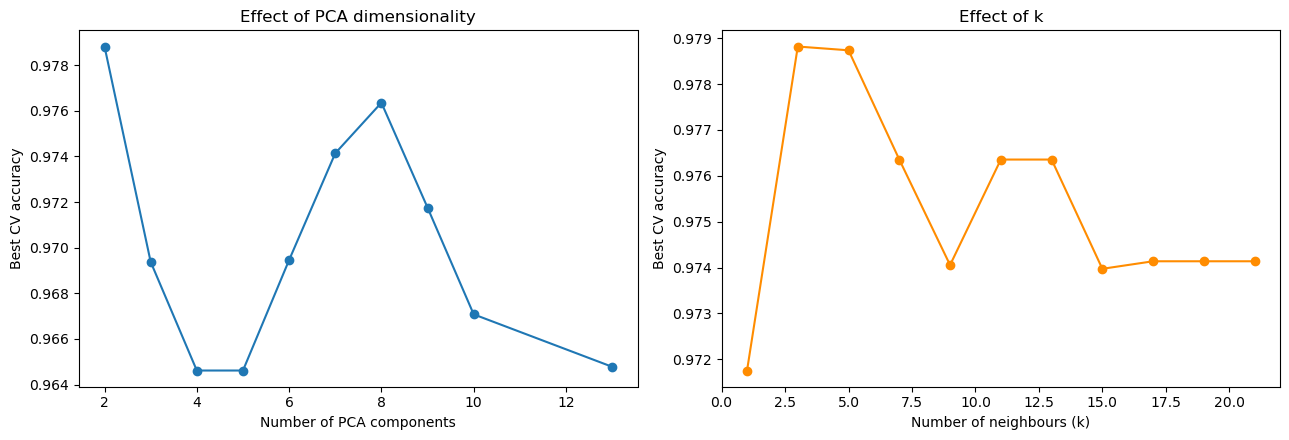

In [65]:
# How do the main hyperparameters affect accuracy? (best score over the other settings)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

by_comp = cv_results.groupby("param_pca__n_components")["mean_test_score"].max()
axes[0].plot(by_comp.index.astype(int), by_comp.values, marker="o")
axes[0].set_xlabel("Number of PCA components")
axes[0].set_ylabel("Best CV accuracy")
axes[0].set_title("Effect of PCA dimensionality")

by_k = cv_results.groupby("param_knn__n_neighbors")["mean_test_score"].max()
axes[1].plot(by_k.index.astype(int), by_k.values, marker="o", color="darkorange")
axes[1].set_xlabel("Number of neighbours (k)")
axes[1].set_ylabel("Best CV accuracy")
axes[1].set_title("Effect of k")

plt.tight_layout()
plt.show()

The winning configuration uses **2 principal components, k = 3, distance-weighted voting and the Euclidean metric**, with a cross-validated accuracy of about 97.9%. The runners-up are within the noise: the standard deviation across folds (about 3 percentage points) is larger than the gaps between the top configurations. A configuration with 8 components and k = 11 to 13 scores almost the same. The tuning curves show that accuracy is high and flat across a wide range of settings, so the model is not fragile with respect to its hyperparameters. Compared with the 95% scaling-only baseline, tuning added roughly 3 percentage points in cross-validation.

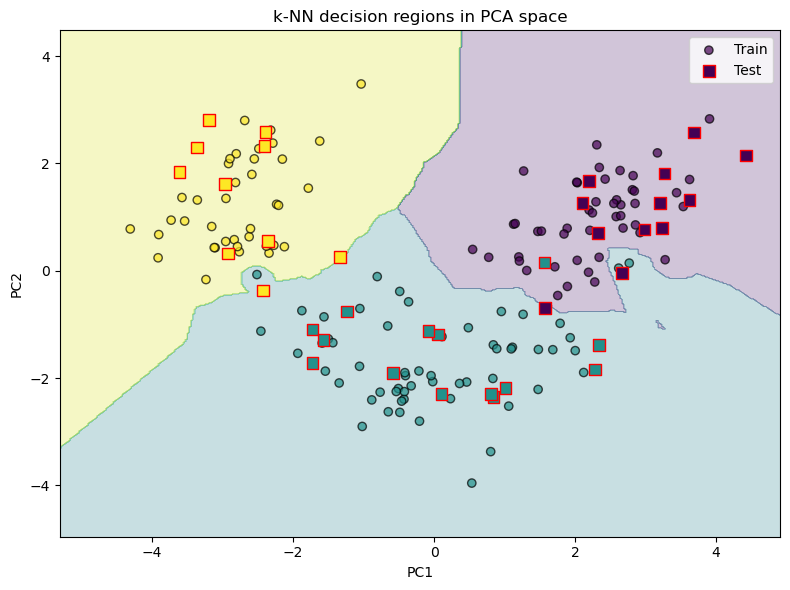

In [66]:
# Decision regions of the tuned model (valid because the winning model works in 2 principal components)
n_comp = grid_search.best_params_["pca__n_components"]

if n_comp == 2:
    scaler_f, pca_f, knn_f = (best_model.named_steps[s] for s in ("scaler", "pca", "knn"))
    Z_train = pca_f.transform(scaler_f.transform(X_train))
    Z_test = pca_f.transform(scaler_f.transform(X_test))

    xx, yy = np.meshgrid(
        np.linspace(Z_train[:, 0].min() - 1, Z_train[:, 0].max() + 1, 400),
        np.linspace(Z_train[:, 1].min() - 1, Z_train[:, 1].max() + 1, 400),
    )
    zz = knn_f.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, zz, alpha=0.25, cmap="viridis")
    plt.scatter(Z_train[:, 0], Z_train[:, 1], c=y_train, cmap="viridis", edgecolor="k", alpha=0.7, label="Train")
    plt.scatter(Z_test[:, 0], Z_test[:, 1], c=y_test, cmap="viridis", edgecolor="red", marker="s", s=70, label="Test")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title("k-NN decision regions in PCA space")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print(f"The best model uses {n_comp} components, so a 2D decision-region plot is not applicable.")

The coloured regions show how the model would label a new wine at any position in PCA space. The Barbera region is well separated from the other two. The boundary between Barolo and Grignolino is more jagged, because wines of the two varieties lie close together there. Test wines (squares with red edges) sitting near that boundary are the ones the model is most likely to get wrong.